In [ ]:
# Authors: Romaric Thiboud <romaric.thiboud@inserm.fr>
#          Marine Vernet <marine.vernet@inserm.fr>
#
# License: BSD (3-clause)

# *******************************************************
#               IMPORT PACKAGES
# *******************************************************

import numpy as np
import pingouin as pg
import mne
import os
import os.path as op
import matplotlib.pyplot as plt
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap 
import seaborn as sns
import scipy.stats
from scipy.stats import ttest_ind
from scipy.stats import t
from scipy.stats import ttest_rel
from collections import defaultdict
from mne.time_frequency import tfr_morlet
from mne.stats import spatio_temporal_cluster_1samp_test
from mne.stats import permutation_cluster_1samp_test
from mne.stats import permutation_cluster_test
from mne.stats import combine_adjacency
from mne.channels import find_ch_adjacency
from mne.viz import plot_topomap
from mne.viz import plot_compare_evokeds
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from pathlib import Path
from sklearn.metrics import roc_auc_score
import pandas as pd
from scipy.stats import pearsonr

from config import *
# *******************************************************
#                   FUNCTIONS
# *******************************************************

def compute_adjacency(epochs, n_times):

    # ************** Create spatial connectivity between sensors **************
    spatial_adjacency, ch_names = find_ch_adjacency(epochs.pick('mag').info, ch_type='mag')

    # Find the missing channel (remove the -2805 included in the name of the channels from channels found in epochs)
    # and then slice the sparse matrix to remove missing channels
    all_ch_names = [ch for ch in ch_names]
    data_ch_names = [ch.split('-')[0] for ch in epochs.pick('mag').info['ch_names']]
    missing_ch = list(set(all_ch_names) - set(data_ch_names))
    missing_idx = all_ch_names.index(missing_ch[0])
    keep_inds = np.setdiff1d(np.arange(spatial_adjacency.shape[0]), missing_idx)
    spatial_adjacency = spatial_adjacency[keep_inds][:, keep_inds]
    mne.viz.plot_ch_adjacency(epochs.info, spatial_adjacency, epochs.pick('mag').info['ch_names'])

    # ************** If you do clustering in space (sensors) and time, compute the time_space adjacency **************
    spatio_temporal_adjacency = combine_adjacency(n_times, spatial_adjacency)

    return spatial_adjacency, spatio_temporal_adjacency

def compute_input_to_cluster_test(X1, X2, epochs, time_range, tfr_ana = False):

    # # ************** If you choose to reduce the time window over which you will do the clustering **************
    times = epochs.times
    time_mask = (times >= time_range[0]) & (times <= time_range[1]) # here we take from -200 ms to 0 before image offset
    time_inds = np.where(time_mask)[0]
    # Slice X to this time window
    if tfr_ana:
        X1 = X1[:, :, :, time_inds]  # shape: (n_subjects, n_channels, freqs, selected_n_times)
        X2 = X2[:, :, :, time_inds]
    else:
        X1 = X1[:, :, time_inds]  # shape: (n_subjects, n_channels, selected_n_times)
        X2 = X2[:, :, time_inds]
    # Update times for plotting later
    times = times[time_inds]

    X_both = [X1, X2]
    X_diff = X1 - X2

    n_observations, n_channels, n_times = X_diff.shape[0], X_diff.shape[1], X_diff.shape[2]  

    return X_both, X_diff, n_channels, n_times, n_observations, times


    # We want to set a critical test statistic (here: F), to determine when
    # clusters are being formed. Using Scipy's percent point function of the F
    # distribution, we can conveniently select a threshold that corresponds to
    # some alpha level that we arbitrarily pick.

    # For an F test we need the degrees of freedom for the numerator
    # (number of conditions - 1) and the denominator (number of observations
    # - number of conditions):
    dfn = n_conditions - 1
    dfd = n_observations - n_conditions

    # Note: we calculate 1 - alpha_cluster_forming to get the critical value
    # on the right tail
    f_thresh = scipy.stats.f.ppf(1 - alpha_cluster_forming, dfn=dfn, dfd=dfd)

    tail = 1

    return f_thresh, tail  

def create_sign_mask(cluster_p_values, clusters, sign_threshold):
    mask = np.zeros_like(clusters[0], dtype=bool) # Initialize empty mask
    for i, p_val in enumerate(cluster_p_values):
        if p_val < sign_threshold:
            mask |= clusters[i]
    return mask

def extract_condition(all_tfrs, condition):
    return [
        all_tfrs[participant][condition]
        for participant in all_tfrs
        if condition in all_tfrs[participant]
    ]

def run_spatio_temporal_one_sample_cluster(diff_array, adjacency, n_permutations=1000, threshold=None, tail=0):

    # Convert list to numpy array: subjects × channels × freqs × times
    # reorder dimensions to fit the function
    data = diff_array.transpose(0, 3, 2, 1)  # subjects × times × freqs × channels

    # Run the one-sample cluster permutation test
    T_obs, clusters, cluster_p_values, _ = spatio_temporal_cluster_1samp_test(
        data,
        n_permutations=n_permutations,
        threshold=threshold,
        tail=tail,
        adjacency=adjacency,
        max_step=1,
        out_type='indices',
        n_jobs=-1
    )

    return T_obs, clusters, cluster_p_values   

def plot_compare_evokeds_raw(
    evokeds_dict,
    picks,
    ax,
    colors=None,
    line_style='-',
    alpha=0.3  # Transparency for the SEM cloud
):
    """
    Plots mean signal with SEM shading across evoked objects.
    """
    for label, evk_list in evokeds_dict.items():
        # times: (n_times,)
        times = evk_list[0].times
        
        # 1. Stack all data: (n_evoked, n_channels, n_times)
        # data = np.stack([evk.data[picks] for evk in evk_list])
        list_keys = list(evokeds_dict.keys())
        if list_keys[0] == 'RP' :
            data = np.stack([evk.get_data(units=dict(grad='fT/cm', mag='fT'), picks= picks) for evk in evk_list])
            label = "crimson"
        else:
            data = np.stack([evk.data[picks] for evk in evk_list])
        
        # 2. Mean across channels: (n_evoked, n_times)
        # This gives us one timecourse per subject/trial
        subject_means = data.mean(axis=1)

        # 3. Calculate Grand Mean and SEM across subjects/evokeds
        y_mean = subject_means.mean(axis=0)
        y_sem = subject_means.std(axis=0) / np.sqrt(len(evk_list))

        # color = None if colors is None else colors.get(label)
        color = "crimson"
        # Plot the main line
        ax.plot(
            times,
            y_mean,
            label=label,
            color=color,
            linewidth=2,
            linestyle=line_style,
            
        )
        ax.grid(True, linestyle=':', alpha=0.6)

        # Plot the SEM Shading
        ax.fill_between(
            times,
            y_mean - y_sem,
            y_mean + y_sem,
            color=color,
            alpha=alpha,
            edgecolor=None
        )
        
    # --- Clean up Aesthetics ---
    ax.axhline(0, color='k', linestyle='-', linewidth=1, alpha=0.5)
    ax.axvline(0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Snap limits to data edges to remove the gaps
    ax.set_xlim(times[0], times[-1])
    ax.set_ylim(np.min(y_mean - y_sem) * 1.1, np.max(y_mean + y_sem) * 1.1)
    
    # ax.legend()
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude (raw units)")
    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)

# *******************************************************
#          DEFINE PATH AND INITALIZE PARAMETERS
# *******************************************************

path_figures_univ = Path(path_figures,'univariate_fig')
if not os.path.exists(path_figures_univ):
    os.makedirs(path_figures_univ)

# Statistical parameters 
permut_type = 'space_time'  # 'space'
sign_threshold = 0.05

# Parameters for time-frequency analysis
Baseline_correction_tfr = True  
time_range = [-1, 1] # time-range to test
sign_threshold = 0.05
freq_analysis = 'both'  


# Do you want to plot individual figures
plot_individual_figures = False  # True 
verbose = True  # False 
saving = True  # False

# Select the best and worst performers for each decoding type (temporal and spectral)
list_roc_auc_temporal = []
list_roc_auc_spectral = []
for n_participant, participant in enumerate(subjects_id):
    # loading the scores to compute ROC AUC for temporal module
    path_scores = Path(op.join(path_output, participant, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
    df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % participant))
    data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == -300]  # Select the time window of interest
    # Compute ROC AUC for temporal module
    list_roc_auc_temporal.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_temporal'].values)) 
    list_roc_auc_spectral.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_riemann'].values))

# Best temporal decoding    
indices_best_temporal = np.argsort(list_roc_auc_temporal)[-9:]  
# Worst temporal decoding
indices_worst_temporal = np.argsort(list_roc_auc_temporal)[:9] 
# Best spectral decoding
indices_best_spectral = np.argsort(list_roc_auc_spectral)[-9:]  
# Worst spectral decoding
indices_worst_spectral = np.argsort(list_roc_auc_spectral)[:9]  

Load data & compute time-frequency decomposition

In [ ]:
# LOOP OVER THE PARTICIPANTS

# initialize list
epochs_list = []

# Container for all subjects' TFRs
all_tfrs = {}
all_tfrs_baselined = {}

for participant in subjects_id:

    print('\n*******************************\n')
    print('Participants:' + participant)

    # ********************* Define Directory ************************
    folder = op.join(path_analyzed_data, participant, 'epochs_megchannels')

    # ***************** Load Preprocessed Epochs ********************
    epo_file = os.path.join(folder, '%s_clean-epo.fif') % (participant)
    epochs = mne.read_epochs(epo_file, verbose=verbose)
    # Rename condition label
    epochs.event_id = {'human': epochs.event_id.pop('button'), 
                       'computer': epochs.event_id.pop('nothing')}
    
    epochs_list.append(epochs)  # Append the epochs to the list
    
    # Define parameters
    conditions = ['human', 'computer']
    freqs = np.arange(8, 30, 1)
    n_cycles = freqs / 2.

    # participant_tfrs = {}
    participant_tfrs_baselined = {}
    for cond in conditions:

        print(f"{participant} - {cond}: Computing TFR...")
        
        power = tfr_morlet(epochs[cond], freqs=freqs, n_cycles=n_cycles,
                        use_fft=True, return_itc=False, average=False, n_jobs=-1)
        
        power_baselined = power.copy().apply_baseline((-1.9, -1.7), mode='logratio')
        participant_tfrs_baselined[cond] = power_baselined.average()

    all_tfrs_baselined[participant] = participant_tfrs_baselined
    
    if plot_individual_figures:
        
        # ******************* plotting epochs ********************
        epochs.plot(title=f'{participant} Epochs') 
        plt.show()

        # ************** plotting topographies *****************
        evoked = epochs['nothing'].average()  # Compute the evoked response
        evoked.plot_topomap(times=[-0.2, -0.1, 0.0], ch_type='mag', colorbar=True)
        plt.suptitle(f'{participant} Topography')
        plt.show()

        # ************** compute and plot the Power Spectral Density (PSD) of the epochs *****************
        psd = epochs.compute_psd(fmin=2.0, fmax=40.0, picks='all', n_jobs=1)
        psd.plot(
            color='blue'  
        )
        plt.title(f'{participant} Epochs - Power Spectral Density')
        plt.show()
        psd.plot_topomap(ch_type="mag", normalize=False, contours=0)
        plt.show()

# Compute evoked at participant level
evoked_human_array = []
evoked_computer_array = []

evoked_human_array = [epochs.pick_types(meg=True, ref_meg=False)['human'].average().get_data(units=dict(grad='fT/cm', mag='fT')) for epochs in epochs_list]
evoked_computer_array = [epochs.pick_types(meg=True, ref_meg=False)['computer'].average().get_data(units=dict(grad='fT/cm', mag='fT')) for epochs in epochs_list]    


*******************************

Participants:s0986
Reading C:\Users\Romar\Documents\PhD_Agency\DATA\data_analyzed\s0986\epochs_megchannels\s0986_clean-epo.fif ...
    Read 5 compensation matrices
    Found the data of interest:
        t =   -2000.00 ...    1000.00 ms
        5 CTF compensation matrices available
Not setting metadata
1042 matching events found
No baseline correction applied
0 projection items activated
s0986 - human: Computing TFR...
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Removing 5 compensators from info because not all compensation channels were picked.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:    5.8s
[Parallel(n_jobs=-1)]: Done 142 tasks      | elapsed:    9.5s
[Parallel(n_jobs=-1)]: Done 274 out of 274 | elapsed:   17.0s finished


Applying baseline correction (mode: logratio)
s0986 - computer: Computing TFR...
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Removing 5 compensators from info because not all compensation channels were picked.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:    4.1s
[Parallel(n_jobs=-1)]: Done 142 tasks      | elapsed:   11.2s
[Parallel(n_jobs=-1)]: Done 274 out of 274 | elapsed:   22.9s finished


Applying baseline correction (mode: logratio)

*******************************

Participants:s0987
Reading C:\Users\Romar\Documents\PhD_Agency\DATA\data_analyzed\s0987\epochs_megchannels\s0987_clean-epo.fif ...
    Read 5 compensation matrices
    Found the data of interest:
        t =   -2000.00 ...    1000.00 ms
        5 CTF compensation matrices available
Not setting metadata
1067 matching events found
No baseline correction applied
0 projection items activated
s0987 - human: Computing TFR...
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Removing 5 compensators from info because not all compensation channels were picked.


...

Applying baseline correction (mode: logratio)

*******************************

Participants:s1130
Reading C:\Users\Romar\Documents\PhD_Agency\DATA\data_analyzed\s1130\epochs_megchannels\s1130_clean-epo.fif ...
    Read 5 compensation matrices
    Found the data of interest:
        t =   -2000.00 ...    1000.00 ms
        5 CTF compensation matrices available
Not setting metadata
1080 matching events found
No baseline correction applied
0 projection items activated
s1130 - human: Computing TFR...
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Removing 5 compensators from info because not all compensation channels were picked.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:    5.3s
[Parallel(n_jobs=-1)]: Done 142 tasks      | elapsed:   12.0s
[Parallel(n_jobs=-1)]: Done 274 out of 274 | elapsed:   20.7s finished


Applying baseline correction (mode: logratio)
s1130 - computer: Computing TFR...
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Removing 5 compensators from info because not all compensation channels were picked.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:    5.1s
[Parallel(n_jobs=-1)]: Done 142 tasks      | elapsed:   12.1s
[Parallel(n_jobs=-1)]: Done 274 out of 274 | elapsed:   20.5s finished


Applying baseline correction (mode: logratio)
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Removing 5 compensators from info because not all compensation channels were picked.
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Removing 5 compensators from info because not all compensation channels were picked.
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Removing 5 compensators from info because not all compensation channels were picked.
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Removing 5 compensators from info because not all compensation channels were picked.
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Removing 5 compensators from info because not all compensation channels were picked.
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Removing 5 compensators from info because not all compensation chan

Temporal analysis (Readiness Potential)

Reading adjacency matrix for ctf275.
Using a threshold of 1.739607
stat_fun(H1): min=-7.3899619692103125 max=7.1990891417269385
Running initial clustering …
Found 91 clusters


  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).

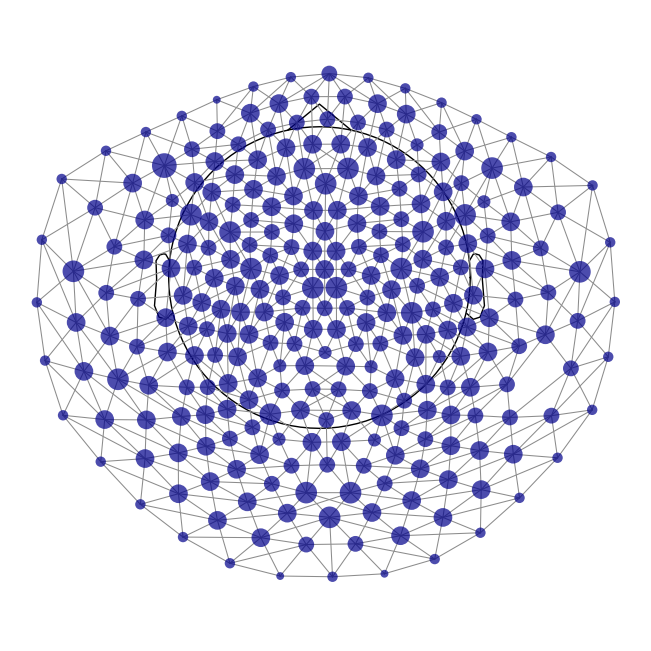

In [ ]:
# ################ cluster based permutation in time+space #####################################
# prepare the input to the clustering algos
time_range = [-2, 0] # Here you can reduced the time-range that you want to test
X_both, X_diff, n_channels, n_times, n_observations, times = compute_input_to_cluster_test(np.array(evoked_human_array), np.array(evoked_computer_array), epochs, time_range)
spatial_adjacency, spatio_temporal_adjacency = compute_adjacency(epochs, n_times)

# The clustering happens in space and time
Xt = np.transpose(X_diff, (0, 2, 1))
T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
    Xt, n_permutations=1000, threshold=None, tail=1, seed=42,
    adjacency=spatio_temporal_adjacency, out_type='indices', n_jobs=-1, verbose=True)

# select the significant cluster(s)
good_cluster_inds = np.where(cluster_p_values < sign_threshold)[0]

# Plot the significant clusters
evoked_human = [epochs.pick_types(meg=True, ref_meg=False)['human'].average() for epochs in epochs_list]
evoked_computer = [epochs.pick_types(meg=True, ref_meg=False)['computer'].average() for epochs in epochs_list]

all_diff_evokeds=[]
for human_evoked, computer_evoked in zip(evoked_human, evoked_computer):
    diff_evoked = mne.combine_evoked([human_evoked, computer_evoked], weights=[1, -1])
    all_diff_evokeds.append(diff_evoked)

name1 = 'RP'
colors = {name1: "crimson"}
evokeds_RP = {name1: all_diff_evokeds}

significant_clusters_RP = []
# loop over clusters
for i_clu, clu_idx in enumerate(good_cluster_inds):
    # unpack cluster information, get unique indices
    times_inds, space_inds = np.squeeze(clusters[clu_idx])

    ch_inds = np.unique(space_inds)
    ch_inds_RP = ch_inds
    time_inds = np.unique(times_inds)
    
    # get topography for T stat 
    f_map = T_obs[time_inds, ...].mean(axis=0)
    
    # Careful, you want to have the convert time_inds for the restricted time window to the original time window
    matching_indices = np.where(np.isin(epochs.times, times[time_inds]))[0]

    # get signals at the sensors contributing to the cluster
    sig_times = epochs.times[matching_indices]

    print(f"Cluster #{i_clu + 1}: p-value = {cluster_p_values[clu_idx]:.4f}, "
            f"t-statistic = [{T_obs[time_inds, ...].min():.2f}, {T_obs[time_inds, ...].max():.2f}], "
            f"Channels = {len(ch_inds)}, Time range = [{sig_times[0]:.3f}, {sig_times[-1]:.3f}] s")

    # create spatial mask
    mask = np.zeros((f_map.shape[0], 1), dtype=bool)
    mask[ch_inds, :] = True
    
    # get topography of the fT activity difference average on the group
    # and retrive mask for time point of interest
    cluster_by_time = [[] for _ in range(n_times)]
    # Fill it
    for s, t in zip(space_inds, times_inds):
        cluster_by_time[t].append(s)

    topo_dict = {}
    time_interest_RP = [-0.5, -0.250, -0.1, 0]
    for t in time_interest_RP:
        time_cluster = np.argmin(np.abs(times - t))
        time_epo = np.argmin(np.abs(times - t))
        
        tmp = np.mean(X_diff, axis=0)[:, time_epo]
        mask_topo = np.zeros((f_map.shape[0], 1), dtype=bool)
        mask_topo[cluster_by_time[time_cluster], :] = True
        topo_dict[t] = {"topo": tmp, "mask": mask_topo}
    
    # Store indices and relevant time points
    significant_clusters_RP.append({
        'idx': clu_idx,
        'chan_inds': np.unique(space_inds),
        'full_space_inds': space_inds,
        'full_time_inds': times_inds,
        'sig_times': sig_times,
        'f_map': f_map,
        'mask_f_map': mask,
        'topomap_at_time': topo_dict,
        'epo_info': epochs.pick('mag').info,
        'time_interest_RP': time_interest_RP
    })

Time-frequency analysis (ERD)

In [ ]:
# prepare the input to the clustering algos
# Extract a list of TFRs for each condition from the dictionary
tfr_human = extract_condition(all_tfrs_baselined, 'human')
tfr_computer = extract_condition(all_tfrs_baselined, 'computer')

array_tfr_human = np.array([item.data for item in tfr_human])
array_tfr_computer = np.array([item.data for item in tfr_computer])

human_tfr_list = [v['human'] for v in all_tfrs_baselined.values()]
computer_tfr_list = [v['computer'] for v in all_tfrs_baselined.values()]

################### Selected frequency band analysis #########################
alpha_band = (8, 12)
beta_band = (13, 30)

# Human trials 
human_alpha_tfrs = [
    tfr.copy().crop(fmin=alpha_band[0], fmax=alpha_band[1])
    for tfr in human_tfr_list]
human_beta_tfrs = [
    tfr.copy().crop(fmin=beta_band[0], fmax=beta_band[1])
    for tfr in human_tfr_list]
X_alpha_human = np.array([tfr.data for tfr in human_alpha_tfrs])
X_beta_human  = np.array([tfr.data for tfr in human_beta_tfrs])

X_alpha_human_array = np.squeeze(np.mean(X_alpha_human, axis=2))  # Average over frequencies
print(X_alpha_human_array.shape)
X_beta_human_array = np.squeeze(np.mean(X_beta_human, axis=2))  # Average over frequencies
print(X_beta_human_array.shape)
# Computer trials
computer_alpha_tfrs = [
    tfr.copy().crop(fmin=alpha_band[0], fmax=alpha_band[1])
    for tfr in computer_tfr_list]
computer_beta_tfrs = [
    tfr.copy().crop(fmin=beta_band[0], fmax=beta_band[1])
    for tfr in computer_tfr_list]
X_alpha_computer = np.array([tfr.data for tfr in computer_alpha_tfrs])
X_beta_computer  = np.array([tfr.data for tfr in computer_beta_tfrs])

X_alpha_computer_array = np.squeeze(np.mean(X_alpha_computer, axis=2))  # Average over frequencies
print(X_alpha_computer_array.shape)
X_beta_computer_array = np.squeeze(np.mean(X_beta_computer, axis=2))  # Average over frequencies
print(X_beta_computer_array.shape)
# Createepochs objects of grand Averaged data for plotting
list_evoked_tfr_alpha= []
list_evoked_tfr_beta = [] 

list_evoked_tfr_alpha_human = []
list_evoked_tfr_beta_human = []

for n_participant, participant in enumerate(subjects_id):
    tfr_evoked_alpha_human = mne.EvokedArray(X_alpha_human_array[n_participant,:,:]*10, info=human_alpha_tfrs[0].info, tmin=human_alpha_tfrs[0].tmin) # convert log ratio to decibel by multiplyong by 10
    tfr_evoked_alpha_computer = mne.EvokedArray(X_alpha_computer_array[n_participant,:,:]*10, info=computer_alpha_tfrs[0].info, tmin=computer_alpha_tfrs[0].tmin) # convert log ratio to decibel by multiplyong by 10
    evoked_tfr_diff_alpha = mne.combine_evoked([tfr_evoked_alpha_human, tfr_evoked_alpha_computer], weights=[1, -1])
    
    list_evoked_tfr_alpha_human.append(tfr_evoked_alpha_human)
    list_evoked_tfr_alpha.append(evoked_tfr_diff_alpha)
    
    tfr_evoked_beta_human = mne.EvokedArray(X_beta_human_array[n_participant,:,:]*10, info=human_beta_tfrs[0].info, tmin=human_beta_tfrs[0].tmin) # convert log ratio to decibel by multiplyong by 10
    tfr_evoked_beta_computer = mne.EvokedArray(X_beta_computer_array[n_participant,:,:]*10, info=computer_beta_tfrs[0].info, tmin=computer_beta_tfrs[0].tmin) # convert log ratio to decibel by multiplyong by 10
    evoked_tfr_diff_beta = mne.combine_evoked([tfr_evoked_beta_human, tfr_evoked_beta_computer], weights=[1, -1])
    
    list_evoked_tfr_beta_human.append(tfr_evoked_beta_human)
    list_evoked_tfr_beta.append(evoked_tfr_diff_beta)


(18, 274, 361)
(18, 274, 361)
(18, 274, 361)
(18, 274, 361)


In [ ]:
# Combine time frequency univariate anlysis
# Time range for the analysis (in seconds)
time_range = [-2, 1]

time_interest_beta = [-0.750, -0.500, -0.250, -0.1]
time_interest_alpha = [-0.100, 0, 0.250, 0.500]

# Prepare data Time frequency map on MLC52 #
sensor = 'MLC52-2805' 
list_vis_diff_h_c = []
for i in range(len(tfr_computer)):
    # Pick the channel of interest
    this_tfr_h = mne.time_frequency.AverageTFRArray(info=tfr_human[i].info, data=array_tfr_human[i, :, :] * 10, times=tfr_human[i].times, freqs=tfr_human[i].freqs, nave=1).copy().pick_channels([sensor]) # convert log ratio to decibel by multiplying by 10
    this_tfr_c = mne.time_frequency.AverageTFRArray(info=tfr_computer[i].info, data=array_tfr_computer[i, :, :] * 10, times=tfr_computer[i].times, freqs=tfr_computer[i].freqs, nave=1).copy().pick_channels([sensor]) # convert log ratio to decibel by multiplying by 10
    this_tfr = mne.combine_evoked([this_tfr_h, this_tfr_c], weights=[1, -1])
    list_vis_diff_h_c.append(this_tfr)
    
# Compute the grand average of the difference TFRs across participants
ave_tfr_diff = mne.grand_average(list_vis_diff_h_c.copy())

# tfrs = list of AverageTFR objects, length = n_subjects
X = np.array([ tfr.data[0] for tfr in list_vis_diff_h_c])

n_freqs, n_times = X.shape[1], X.shape[2]
adjacency = combine_adjacency( n_freqs, n_times)

# Run the one-sample cluster permutation test
T_obs, clusters, cluster_pvals, H0 = permutation_cluster_1samp_test( X, adjacency=adjacency,
n_permutations=1000, threshold=None, tail=0, out_type='mask', n_jobs=-1, seed=42 )

# create a boolean mask of significant clusters
sig_mask_tfrmap = np.zeros(T_obs.shape, dtype=bool)
for cluster, p in zip(clusters, cluster_pvals):
    if p < 0.05:
        sig_mask_tfrmap |= cluster
        
################### Prepare data spatio-temporal test Beta band ##################

X_both, X_diff, n_channels, n_times, n_observations, times = compute_input_to_cluster_test(
    np.array(X_beta_human_array), np.array(X_beta_computer_array), computer_tfr_list[0], time_range, tfr_ana=False)
spatial_adjacency, spatio_temporal_adjacency = compute_adjacency(computer_tfr_list[0], n_times)

Xt = np.transpose(X_diff, (0, 2, 1))
T_obs, clusters, cluster_p_values, H0 = spatio_temporal_cluster_1samp_test(
Xt,
adjacency=spatio_temporal_adjacency,
n_permutations=1000,
threshold=None,
tail=0,
n_jobs=-1,
seed=42)

# Initialize a list to store data for significant clusters
significant_clusters_beta = []

# select the significant cluster(s)
good_cluster_inds = np.where(cluster_p_values < sign_threshold)[0]
print(f"Number of significant clusters in beta band: {len(good_cluster_inds)}")
for i_clu, clu_idx in enumerate(good_cluster_inds):
    
    # unpack cluster information, get unique indices
    times_inds, space_inds = np.squeeze(clusters[clu_idx])

    ch_inds = np.unique(space_inds)
    ch_inds_beta = ch_inds
    time_inds = np.unique(times_inds)
    
    # get topography for T stat (if you prefer, you could also plot the activity averaged over time)
    f_map = T_obs[time_inds, ...].mean(axis=0)
    
    # Careful, you want to have the convert time_inds for the restricted time window to the original time window
    matching_indices = np.where(np.isin(epochs.times, times[time_inds]))[0]

    # get signals at the sensors contributing to the cluster
    sig_times = epochs.times[matching_indices]

    print("Beta band analysis:")
    print(f"Cluster #{i_clu + 1}: p-value = {cluster_p_values[clu_idx]:.4f}, "
        f"t-statistic = [{T_obs[time_inds, ...].min():.2f}, {T_obs[time_inds, ...].max():.2f}], "
        f"Channels = {len(ch_inds)}, Time range = [{sig_times[0]:.3f}, {sig_times[-1]:.3f}] s")

    # create spatial mask
    mask = np.zeros((f_map.shape[0], 1), dtype=bool)
    mask[ch_inds_beta, :] = True
    
    # get topography of the fT activity difference average on the group
    # and retrive mask for time point of interest
    cluster_by_time = [[] for _ in range(n_times)]
    # Fill it
    for s, t in zip(space_inds, times_inds):
        cluster_by_time[t].append(s)

    topo_dict = {}
    
    for t in time_interest_beta:
        time_cluster = np.argmin(np.abs(times - t))
        time_epo = np.argmin(np.abs(times - t))
        
        tmp = np.mean(X_diff, axis=0)[:, time_epo]*10
        mask_topo = np.zeros((f_map.shape[0], 1), dtype=bool)
        mask_topo[cluster_by_time[time_cluster], :] = True
        topo_dict[t] = {"topo": tmp, "mask": mask_topo}

    # Store indices and relevant time points
    significant_clusters_beta.append({
        'idx': clu_idx,
        'chan_inds': np.unique(space_inds),
        'full_space_inds': space_inds,
        'full_time_inds': times_inds,
        'sig_times': sig_times,
        'f_map': f_map,
        'mask_f_map': mask,
        'topomap_at_time': topo_dict,
        'epo_info': list_evoked_tfr_beta[0].info,
        'time_interest_beta': time_interest_beta
    })

################### Prepare data spatio-temporal test Alpha band ##################

X_both, X_diff, n_channels, n_times, n_observations, times = compute_input_to_cluster_test(
    np.array(X_alpha_human_array), np.array(X_alpha_computer_array), computer_tfr_list[0], time_range, tfr_ana=False)
spatial_adjacency, spatio_temporal_adjacency = compute_adjacency(computer_tfr_list[0], n_times)

Xt = np.transpose(X_diff, (0, 2, 1))
T_obs, clusters, cluster_p_values, H0 = spatio_temporal_cluster_1samp_test(
Xt,
adjacency=spatio_temporal_adjacency,
n_permutations=1000,
threshold=None,
tail=0,
n_jobs=-1,
seed=42)

# Initialize a list to store data for significant clusters
significant_clusters_alpha = []

# select the significant cluster(s)
good_cluster_inds = np.where(cluster_p_values < sign_threshold)[0]
print(f"Number of significant clusters in alpha band: {len(good_cluster_inds)}")
for i_clu, clu_idx in enumerate(good_cluster_inds):
    
    # unpack cluster information, get unique indices
    times_inds, space_inds = np.squeeze(clusters[clu_idx])

    ch_inds = np.unique(space_inds)
    ch_inds_alpha = ch_inds
    time_inds = np.unique(times_inds)
    
    # get topography for T stat (if you prefer, you could also plot the activity averaged over time)
    f_map = T_obs[time_inds, ...].mean(axis=0)
    
    # Careful, you want to have the convert time_inds for the restricted time window to the original time window
    matching_indices = np.where(np.isin(epochs.times, times[time_inds]))[0]

    # get signals at the sensors contributing to the cluster
    sig_times = epochs.times[matching_indices]

    print("Alpha band analysis:")
    print(f"Cluster #{i_clu + 1}: p-value = {cluster_p_values[clu_idx]:.4f}, "
        f"t-statistic = [{T_obs[time_inds, ...].min():.2f}, {T_obs[time_inds, ...].max():.2f}], "
        f"Channels = {len(ch_inds)}, Time range = [{sig_times[0]:.3f}, {sig_times[-1]:.3f}] s")


    # create spatial mask
    mask = np.zeros((f_map.shape[0], 1), dtype=bool)
    mask[ch_inds_alpha, :] = True
    
    # get topography of the fT activity difference average on the group
    # and retrive mask for time point of interest
    cluster_by_time = [[] for _ in range(n_times)]
    # Fill it
    for s, t in zip(space_inds, times_inds):
        cluster_by_time[t].append(s)
              
    topo_dict = {}
    for t in time_interest_alpha:
        time_cluster = np.argmin(np.abs(times - t))
        time_epo = np.argmin(np.abs(times - t))
        
        tmp = np.mean(X_diff, axis=0)[:, time_epo]*10
        mask_topo = np.zeros((f_map.shape[0], 1), dtype=bool)
        mask_topo[cluster_by_time[time_cluster], :] = True
        topo_dict[t] = {"topo": tmp, "mask": mask_topo}

    # Store indices and relevant time points
    significant_clusters_alpha.append({
        'idx': clu_idx,
        'chan_inds': np.unique(space_inds),
        'full_space_inds': space_inds,
        'full_time_inds': times_inds,
        'sig_times': sig_times,
        'f_map': f_map,
        'mask_f_map': mask,
        'topomap_at_time': topo_dict,
        'epo_info': list_evoked_tfr_alpha[0].info,
    })

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy functi

  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

Reading adjacency matrix for ctf275.
Using a threshold of 2.109816
stat_fun(H1): min=-8.519492679906426 max=7.17063149004131
Running initial clustering …
Found 103 clusters


  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

Number of significant clusters in beta band: 1
Beta band analysis:
Cluster #1: p-value = 0.0010, t-statistic = [-8.52, 2.81], Channels = 272, Time range = [-1.067, 0.492] s
Reading adjacency matrix for ctf275.
Using a threshold of 2.109816
stat_fun(H1): min=-7.344205299071079 max=4.5595345860259835
Running initial clustering …
Found 112 clusters


  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

Number of significant clusters in alpha band: 1
Alpha band analysis:
Cluster #1: p-value = 0.0050, t-statistic = [-7.34, 3.03], Channels = 238, Time range = [-0.242, 1.000] s


All the univariate analysis in one figure

Plotting RP results
Plotting beta results
Plotting alpha results
No baseline correction applied
No baseline correction applied


C:\Users\Romar\AppData\Local\Temp\ipykernel_50788\1692047571.py:289: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_tfr.set_xticklabels([f"{int(x*1000)}" for x in xticks])


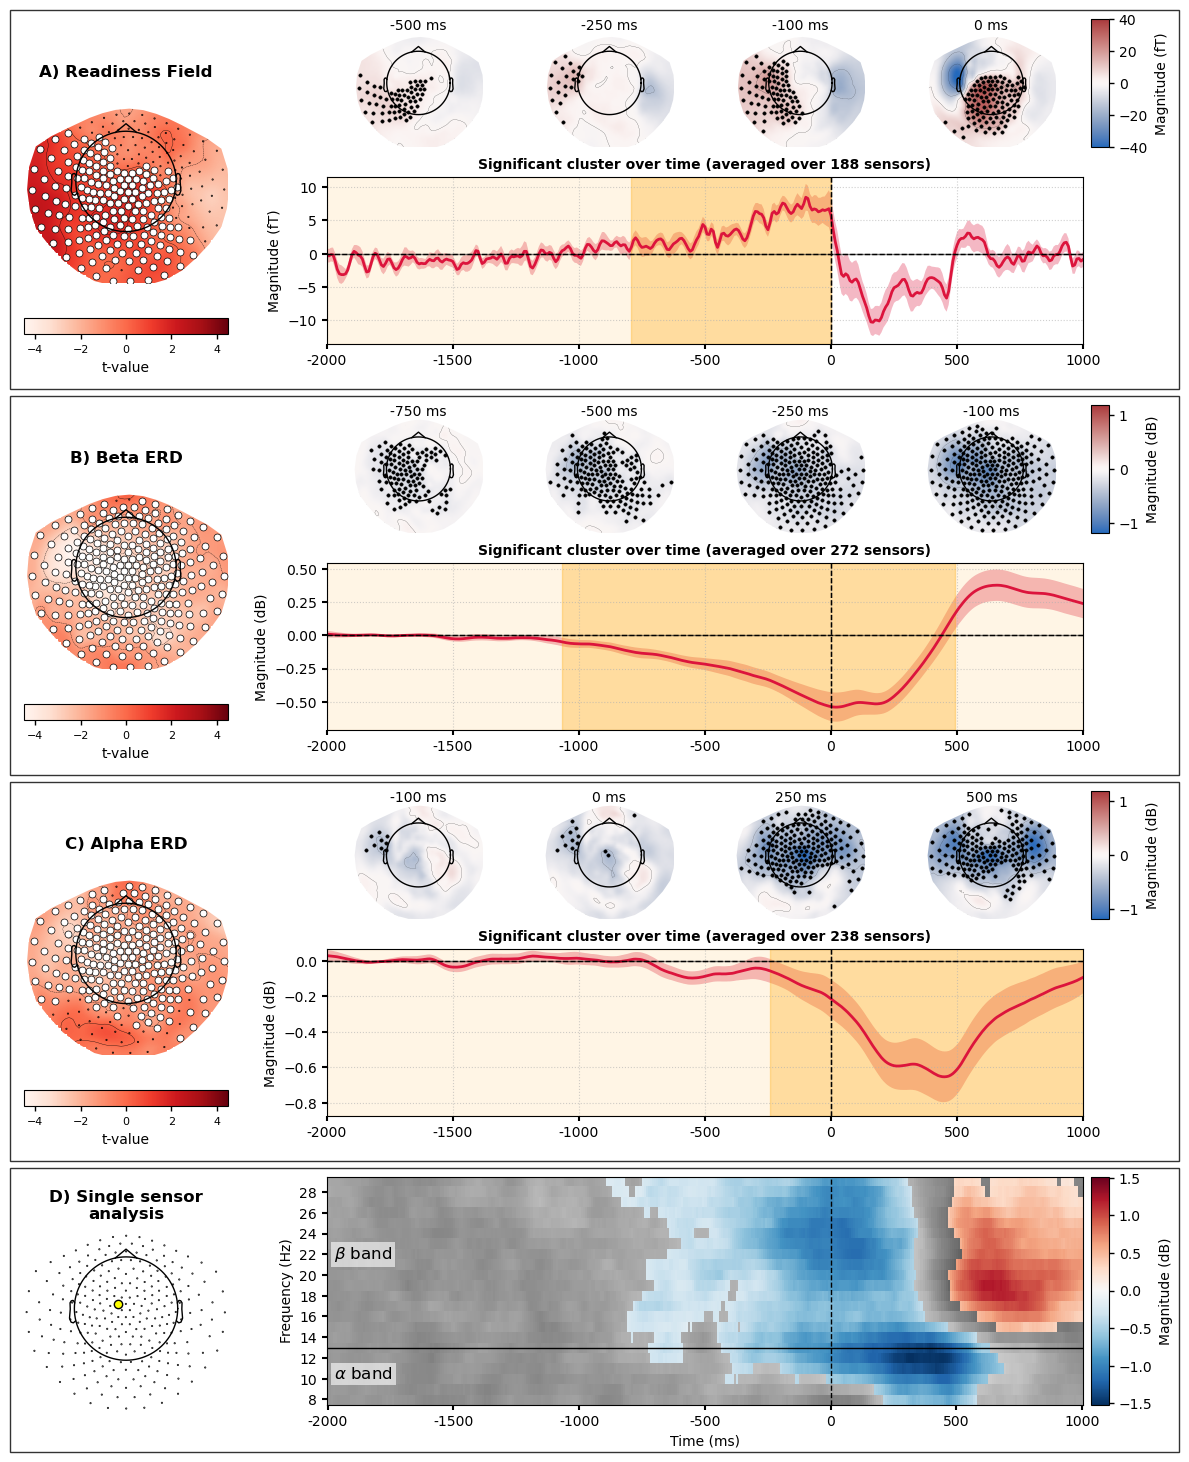

In [ ]:
#################### Plot RP + ERD same figure ############################

clusters_tests = {
    'RP': significant_clusters_RP,
    'beta': significant_clusters_beta,
    'alpha': significant_clusters_alpha}

fig = plt.figure(figsize=(14, 18), constrained_layout=False)

# Main vertical structure:
#   3 repeated blocks (Rp, beta ERD, alpha ERD) each containing:
#   - full cluster extent topomap
#   - 4 small topomaps at selected time points + colorbar
#   - time series of the cluster over time
#   1 bottom "time-frequency map" block

outer = GridSpec(
    nrows=4,
    ncols=1,
    height_ratios=[1, 1, 1, 0.7],
    hspace=0.2,
    figure=fig
)

# ============================================================
# Repeated blocks (3 rows)
# ============================================================

for i, test_name in enumerate(clusters_tests.keys()):
    print(f"Plotting {test_name} results")
    # Each block:
    # left full cluster extent topomap
    # right panel containing:
    #   top row = 4 small topomaps + colorbar
    #   bottom row = time series

    block = GridSpecFromSubplotSpec(
        nrows=1,
        ncols=2,
        width_ratios=[0.6, 2.3],
        wspace=0.2,
        subplot_spec=outer[i]
    )

    # Plotting parameters :
    if test_name == 'RP':
        vlim = (-40, 40)
        title_cbar = "Magnitude (fT)"
        time_range = [-2, 0]
        title_topo_tval = "A) Readiness Field"
    else:
        # vlim = (-0.12, 0.12)
        vlim = (-1.2, 1.2)
        title_cbar = "Magnitude (dB)"
        time_range = [-2, 1]
        if test_name == "beta":
            title_topo_tval = 'B) Beta ERD'
        else:
            title_topo_tval = 'C) Alpha ERD'

    # --------------------------------------------------------
    # LEFT: Large topomap
    # --------------------------------------------------------
    ax_topo_large = fig.add_subplot(block[0, 0])
    f_evoked = mne.EvokedArray(clusters_tests[test_name][0]['f_map'][:, np.newaxis], epochs.pick('mag').info, tmin=0)
    f_evoked.plot_topomap(
        times=0,
        axes=ax_topo_large,
        show=False,
        cmap="Reds",
        mask=clusters_tests[test_name][0]['mask_f_map'],
        mask_params=dict(markersize=10),
        colorbar=False,
        scalings = dict(eeg=1, mag=1, grad=1),
        vlim=(-4.5, 4.5)
    )
    # ax_topo_large.set_title(f"{title_topo_tval} \n ({clusters_tests[test_name][0]['chan_inds'].shape[0]} sensors)", fontsize=12, weight='bold', linespacing=1.5, pad=-0.2)
    ax_topo_large.set_title(f"{title_topo_tval}", fontsize=12, weight='bold', linespacing=1.5, pad=0.8)


    cax = inset_axes(
        ax_topo_large,
        width="100%",
        height="8%",
        loc='lower center',
        bbox_to_anchor=(0, -0.25, 1, 1),
        bbox_transform=ax_topo_large.transAxes,
        borderpad=0
    )
    cbar = fig.colorbar(ax_topo_large.images[0], cax=cax, orientation='horizontal')
    cbar.set_label('t-value', fontsize=10, labelpad=5)
    cbar.ax.tick_params(labelsize=8 , width=1 )


    # --------------------------------------------------------
    # RIGHT side structure
    # --------------------------------------------------------
    right = GridSpecFromSubplotSpec(
        nrows=2,
        ncols=5,
        height_ratios=[1.0, 1.3],
        width_ratios=[1, 1, 1, 1, 0.1],
        hspace=0.2,
        wspace=0.05,
        subplot_spec=block[0, 1]
    )

    # mask parameters for topomaps
    mask_params = dict(markersize=5, marker='o', markerfacecolor='k', markeredgecolor='k', markeredgewidth=0.5)

    # Small topomaps (top row)
    topo_axes = []
    for j in range(4):
        
        time_point_interest = np.array(list(clusters_tests[test_name][0]['topomap_at_time'].keys()))[j]

        ax = fig.add_subplot(right[0, j])

        topo_axes.append(ax)
        # Use the info from your existing TFR object
        evoked_tmp = mne.EvokedArray(clusters_tests[test_name][0]['topomap_at_time'][time_point_interest]['topo'][:, np.newaxis], clusters_tests[test_name][0]['epo_info'], tmin=0) 
        
        # Plot into the specific GridSpec axis
        evoked_tmp.plot_topomap(
            times=0,
            axes=ax,
            show=False,
            mask=clusters_tests[test_name][0]['topomap_at_time'][time_point_interest]['mask'],
            mask_params=mask_params,
            colorbar=False, 
            vlim=vlim,
            scalings=dict(eeg=1, mag=1, grad=1),
            cmap= sns.color_palette("vlag", as_cmap=True),
            sensors=False
        )
        
        # ax.set_title(f"{int(time_point_interest*1000)} ms", fontsize=10, fontweight='bold', y=0.85)
        ax.set_title(f"{int(time_point_interest*1000)} ms", fontsize=10, y=0.85)

    # # Place the colorbar in the last column of the first row
    im = topo_axes[-1].images[0] 
    cax = fig.add_subplot(right[0, 4])
    cbar = plt.colorbar(im, cax=cax)

    cbar.set_label(title_cbar, fontsize=10 , rotation=90, labelpad=5)
    cbar.ax.tick_params(labelsize=10 , width=1 )


    # # Time series (bottom row spanning all columns)

    ax_ts = fig.add_subplot(right[1, 0:4])

    title_timeseries = f"Significant cluster over time (averaged over {clusters_tests[test_name][0]['chan_inds'].shape[0]} sensors)"

    tmp1 = len(clusters_tests[test_name][0]['chan_inds'])

    if test_name == 'RP':
        
        name1 = 'RP'
        colors2 = {name1: "crimson"}
        evokeds = evokeds_RP

    elif test_name == 'beta':

        name1 = 'Beta ERD'
        colors2 = {name1: "crimson"}
        evokeds = {name1: list_evoked_tfr_beta}

    elif test_name == 'alpha':
        name1 = 'Alpha ERD'
        colors2 = {name1: "crimson"}
        evokeds = {name1: list_evoked_tfr_alpha}

    plot_compare_evokeds_raw(
        evokeds,
        picks=clusters_tests[test_name][0]['full_space_inds'],
        ax=ax_ts,
        colors=colors2,
    )

    ax_ts.set_title(title_timeseries, fontsize=10, weight='bold')  # Increase fontsize as desired

    ax_ts.axhline(0, color='k', linestyle='--', linewidth=1, alpha=1)
    ax_ts.axvline(0, color='k', linestyle='--', linewidth=1, alpha=1)

    # Set x-axis in milliseconds
    xticks = ax_ts.get_xticks()
    ax_ts.set_xticks(xticks)
    ax_ts.set_xticklabels([f"{int(x*1000)}" for x in xticks])
    # ax_ts.set_xlabel("Time (ms)", fontsize=10 )
    ax_ts.set_xlabel("", fontsize=10 )
    ax_ts.set_ylabel(title_cbar, fontsize=10 )
    ax_ts.tick_params(axis='both', which='major', labelsize=10 , width=1.5 )

    # Temporal cluster extent
    sign_times2 = clusters_tests[test_name][0]['sig_times']
    ymin, ymax = ax_ts.get_ylim()
    ax_ts.fill_betweenx((ymin, ymax), sign_times2[0], sign_times2[-1], color="orange", alpha=0.3, label='Significant Time Range')
    ax_ts.fill_betweenx((ymin, ymax), time_range[0], time_range[-1], color="orange", alpha=0.1, label='Tested Time Range')

    # ------------------------------------------------------------
    # Draw border around rows of plots
    # ------------------------------------------------------------
    pad_right = 0.05
    pad_left = 0.01
    pad_top = 0.005
    pad_bottom = 0.025

    x0 = min(ax_ts.get_position().x0,
            cax.get_position().x0,
            ax_topo_large.get_position().x0) - pad_left

    y0 = min(ax_ts.get_position().y0,
            cax.get_position().y0,
            ax_topo_large.get_position().y0) - pad_bottom

    x1 = max(ax_ts.get_position().x1,
            cax.get_position().x1,
            ax_topo_large.get_position().x1) + pad_right

    y1 = max(ax_ts.get_position().y1,
            cax.get_position().y1,
            ax_topo_large.get_position().y1) + pad_top

    # Rectangle
    rect = patches.Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        transform=fig.transFigure,
        fill=False,
        edgecolor='black',
        linewidth=1,
        alpha=0.8
    )

    fig.add_artist(rect)

# ============================================================
# Bottom block: time-frequency map + colorbar
# ============================================================

bottom_block = GridSpecFromSubplotSpec(
    nrows=1,
    ncols=2,
    width_ratios=[0.6, 2.3],
    wspace=0.2,
    hspace=0.2,
    subplot_spec=outer[-1]
)

bottom_right = GridSpecFromSubplotSpec(
    nrows=1,
    ncols=5,
    height_ratios=[1.3],
    width_ratios=[1, 1, 1, 1, 0.1],
    hspace=0.2,
    wspace=0.05,
    subplot_spec=bottom_block[0, 1]
)

ax_tfr = fig.add_subplot(bottom_right[0, 0:4])
cax_tfr = fig.add_subplot(bottom_right[0, 4])

ave_tfr_diff.plot([0], axes=ax_tfr, cmap='Greys', colorbar=False, show=False)

# B. Plot Foreground (Significant clusters)
# We set colorbar=False here because we will manually handle it 
ave_tfr_diff.plot([0], axes=ax_tfr, mask=sig_mask_tfrmap, mask_style='mask', 
                cmap='RdBu_r', colorbar=False, show=False)

xticks = ax_tfr.get_xticks()
ax_tfr.set_xticklabels([f"{int(x*1000)}" for x in xticks])
ax_tfr.set_xlabel('Time (ms)', fontsize=10)
ax_tfr.set_ylabel('Frequency (Hz)', fontsize=10)

fmin, fmax = 8.0, 29.0
freq_ticks = np.arange(fmin, fmax + 1, 2)
ax_tfr.set_yticks(freq_ticks)
ax_tfr.set_yticklabels(freq_ticks.astype(int), fontsize=10)
ax_tfr.tick_params(axis='both', which='major', labelsize=10, width=1.5)

ax_tfr.axvline(x=0, color='black', linestyle='--', linewidth=1)
ax_tfr.axhline(y=13, color='black', linestyle='-', linewidth=1)

# D. Handle the Colorbar manually in cax3_2
# We grab the image artist from the axes to create the colorbar
im = ax_tfr.images[-1] 
plt.colorbar(im, cax=cax_tfr)
cax_tfr.set_ylabel('Magnitude (dB)', fontsize=10, labelpad=5)
cax_tfr.tick_params(labelsize=10, width=1)

ax_tfr.text(
    0.01, 0.7, r'$\beta$ band',
    transform=ax_tfr.transAxes,
    fontsize=12,
    color='black',
    va='top',
    ha='left',
    bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=2)
)

ax_tfr.text(
    0.01, 0.1, r'$\alpha$ band',
    transform=ax_tfr.transAxes,
    fontsize=12,
    color='black',
    va='bottom',
    ha='left',
    bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=2)
)

# # E. Plot topomap on the left
info = list_evoked_tfr_beta[0].info
ch_name = ave_tfr_diff.ch_names[0]
ch_idx = info['ch_names'].index(ch_name)

# 1D arrays are fine here
data_1d = np.zeros(len(info['ch_names']))
mask_1d = np.zeros(len(info['ch_names']), dtype=bool)
mask_1d[ch_idx] = True

ax_topo_sensor = fig.add_subplot(bottom_block[0, 0])

# Move sensor axes lower
pos = ax_topo_sensor.get_position()
ax_topo_sensor.set_position([
    pos.x0,          # keep same x
    pos.y0 - 0.01,   # move downward
    pos.width,
    pos.height
])

# Create a colormap that only contains the color white
white_cmap = ListedColormap(['white'])

plot_topomap(
    data_1d,
    info,
    axes=ax_topo_sensor,
    mask=mask_1d,
    show=False,
    contours=0,         
    cmap=white_cmap,   
    vlim=(0, 0),           
    mask_params=dict(
        marker='o',
        markerfacecolor='yellow',
        markeredgecolor='black',
        markersize=6
    )
)

ax_topo_sensor.set_title(
    'D) Single sensor\nanalysis',
    fontsize=12,
    weight='bold',
    y=0.90
)

# ------------------------------------------------------------
# Draw border around rows of plots
# ------------------------------------------------------------
# Plot border (TFR map panel)
pad_right = 0.05
pad_left = 0.01
pad_top = 0.005
pad_bottom = 0.023

x0 = min(ax_topo_sensor.get_position().x0,
         ax_tfr.get_position().x0,
         cax_tfr.get_position().x0) - pad_left

y0 = min(ax_topo_sensor.get_position().y0,
         ax_tfr.get_position().y0,
         cax_tfr.get_position().y0) - pad_bottom

x1 = max(ax_topo_sensor.get_position().x1,
         ax_tfr.get_position().x1,
         cax_tfr.get_position().x1) + pad_right

y1 = max(ax_topo_sensor.get_position().y1,
         ax_tfr.get_position().y1,
         cax_tfr.get_position().y1) + pad_top

# Rectangle
rect = patches.Rectangle(
    (x0, y0),
    x1 - x0,
    y1 - y0,
    transform=fig.transFigure,
    fill=False,
    edgecolor='black',
    linewidth=1,
    alpha=0.8
)
fig.add_artist(rect)

plt.show()

Plot relationship between Univariate and Multivariate results

In [ ]:
# Test difference in RP and ERD amplitude between best decoding and worst decoding participants 
# Name of the condition
name1 = 'Best Decoding'
name2 = 'Worst Decoding'

# Custom function for independent t-test
def stat_fun(*args):
    return ttest_ind(args[0], args[1], axis=0)[0]

# 18 subjects, independent test (df = 18-2)
p_threshold = 0.05
df = 16
# We use p/2 for a two-tailed test
thres = t.ppf(1 - p_threshold / 2, df=df)

# first compute the difference between computer and human than select the evoked for the best and worst temporal decoding performance to plot them on the same figure
list_evoked_human = [epochs.pick_types(meg=True, ref_meg=False)['human'].average() for epochs in epochs_list]
list_evoked_computer = [epochs.pick_types(meg=True, ref_meg=False)['computer'].average() for epochs in epochs_list]
# Pick the channels that are part of the group level cluster 
list_evoked_human = [evoked.copy().pick_channels([epochs_list[i].ch_names[j] for j in ch_inds_RP]) for i, evoked in enumerate(list_evoked_human)]
list_evoked_computer = [evoked.copy().pick_channels([epochs_list[i].ch_names[j] for j in ch_inds_RP]) for i, evoked in enumerate(list_evoked_computer)]

evoked_human_RP_best = [list_evoked_human[i] for i in indices_best_temporal]
evoked_human_RP_worst = [list_evoked_human[i] for i in indices_worst_temporal]
evoked_computer_RP_best = [list_evoked_computer[i] for i in indices_best_temporal]
evoked_computer_RP_worst = [list_evoked_computer[i] for i in indices_worst_temporal]

evoked_human_RP_best_crop = [evoked_human_RP_best[i].copy().crop(tmin=-2, tmax=0) for i in range(len(evoked_human_RP_best))]
evoked_human_RP_worst_crop = [evoked_human_RP_worst[i].copy().crop(tmin=-2, tmax=0) for i in range(len(evoked_human_RP_worst))]
evoked_computer_RP_best_crop = [evoked_computer_RP_best[i].copy().crop(tmin=-2, tmax=0) for i in range(len(evoked_computer_RP_best))]
evoked_computer_RP_worst_crop = [evoked_computer_RP_worst[i].copy().crop(tmin=-2, tmax=0) for i in range(len(evoked_computer_RP_worst))]

evoked_diff_RP_best = [mne.combine_evoked([evoked_human_RP_best[i], evoked_computer_RP_best[i]], weights=[1, -1]) for i in range(len(evoked_human_RP_best))]
evoked_diff_RP_worst = [mne.combine_evoked([evoked_human_RP_worst[i], evoked_computer_RP_worst[i]], weights=[1, -1]) for i in range(len(evoked_human_RP_worst))]

evoked_diff_RP_best_crop = [mne.combine_evoked([evoked_human_RP_best_crop[i], evoked_computer_RP_best_crop[i]], weights=[1, -1]) for i in range(len(evoked_human_RP_best_crop))]
evoked_diff_RP_worst_crop = [mne.combine_evoked([evoked_human_RP_worst_crop[i], evoked_computer_RP_worst_crop[i]], weights=[1, -1]) for i in range(len(evoked_human_RP_worst_crop))]

list_array_RP_diff_best = [evoked_diff_RP_best[i].data.mean(axis=0) for i in range(len(evoked_diff_RP_best))]
list_array_RP_diff_worst = [evoked_diff_RP_worst[i].data.mean(axis=0) for i in range(len(evoked_diff_RP_worst))]

list_array_RP_diff_best_crop = [evoked_diff_RP_best_crop[i].data.mean(axis=0) for i in range(len(evoked_diff_RP_best_crop))]
list_array_RP_diff_worst_crop = [evoked_diff_RP_worst_crop[i].data.mean(axis=0) for i in range(len(evoked_diff_RP_worst_crop))]

evokeds_diff_RP = {
    name1: mne.grand_average(evoked_diff_RP_best),
    name2: mne.grand_average(evoked_diff_RP_worst)
}

X_both =  [np.array(list_array_RP_diff_best_crop) , np.array(list_array_RP_diff_worst_crop)]
T_obs_diff_RP, clusters_diff_RP, cluster_p_values_diff_RP, H0 = permutation_cluster_test(
  X_both, n_permutations=1000, threshold=thres, tail=0, seed=42, stat_fun=stat_fun,
    adjacency=None, out_type='indices', n_jobs=-1, verbose=True)

########################################################################################
# Test for significant difference between high and low decoding groups for ERD amplitude 
########################################################################################

# Pick the channels that are part of the group level cluster 
list_evoked_tfr_beta_reduced = [evoked.copy().pick_channels([epochs_list[i].ch_names[j] for j in ch_inds_beta]) for i, evoked in enumerate(list_evoked_tfr_beta)]
list_evoked_tfr_alpha_reduced = [evoked.copy().pick_channels([epochs_list[i].ch_names[j] for j in ch_inds_alpha]) for i, evoked in enumerate(list_evoked_tfr_alpha)]


evoked_beta_best = [list_evoked_tfr_beta_reduced[i] for i in indices_best_spectral]
evoked_beta_worst = [list_evoked_tfr_beta_reduced[i] for i in indices_worst_spectral]
evokeds_beta = {
    name1: mne.grand_average(evoked_beta_best),
    name2: mne.grand_average(evoked_beta_worst)
}

evoked_alpha_best = [list_evoked_tfr_alpha_reduced[i] for i in indices_best_spectral]
evoked_alpha_worst = [list_evoked_tfr_alpha_reduced[i] for i in indices_worst_spectral]
evokeds_alpha = {
    name1: mne.grand_average(evoked_alpha_best),
    name2: mne.grand_average(evoked_alpha_worst)
}

list_array_beta_best = [evoked_beta_best[i].data.mean(axis=0) for i in range(len(evoked_beta_best))]
list_array_beta_worst = [evoked_beta_worst[i].data.mean(axis=0) for i in range(len(evoked_beta_worst))]
list_array_alpha_best = [evoked_alpha_best[i].data.mean(axis=0) for i in range(len(evoked_alpha_best))]
list_array_alpha_worst = [evoked_alpha_worst[i].data.mean(axis=0) for i in range(len(evoked_alpha_worst))]

X_both =  [np.array(list_array_beta_worst), np.array(list_array_beta_best)]
# The clustering happens in space and time
T_obs_beta, clusters_beta, cluster_p_values_beta, H0 = permutation_cluster_test(
  X_both, n_permutations=1000, threshold=thres, tail=0, seed=42, stat_fun=stat_fun,
    adjacency=None, out_type='indices', n_jobs=-1, verbose=True)

X_both =  [np.array(list_array_alpha_worst), np.array(list_array_alpha_best)]
# The clustering happens in space and time
T_obs_alpha, clusters_alpha, cluster_p_values_alpha, H0 = permutation_cluster_test(
  X_both, n_permutations=1000, threshold=thres, tail=0, seed=42, stat_fun=stat_fun,
    adjacency=None, out_type='indices', n_jobs=-1, verbose=True)


# Create 3 masks for significant clusters
sig_mask_beta = np.zeros_like(times, dtype=bool)
for cluster_idx, p_val in enumerate(cluster_p_values_beta):
    if p_val < 0.05:
        sig_mask_beta[clusters_beta[cluster_idx]] = True
        
sig_mask_alpha = np.zeros_like(times, dtype=bool)
for cluster_idx, p_val in enumerate(cluster_p_values_alpha):
    if p_val < 0.05:
        sig_mask_alpha[clusters_alpha[cluster_idx]] = True

sig_mask_diff_RP = np.zeros_like(times, dtype=bool)
for cluster_idx, p_val in enumerate(cluster_p_values_diff_RP):
    if p_val < 0.05:
        sig_mask_diff_RP[clusters_diff_RP[cluster_idx]] = True


# print temporal extent of significant clusters
print("Significant clusters for beta band:")
for cluster_idx, p_val in enumerate(cluster_p_values_beta):
    if p_val < 0.05:
        print(f"Cluster {cluster_idx}: p = {p_val:.3f}")
        print("Temporal extent:", times[clusters_beta[cluster_idx]])

print("Significant clusters for alpha band:")
for cluster_idx, p_val in enumerate(cluster_p_values_alpha):
    if p_val < 0.05:
        print(f"Cluster {cluster_idx}: p = {p_val:.3f}")
        print(f"Temporal extent: {times[clusters_alpha[cluster_idx]]}")

print("Significant clusters for RP difference:")
for cluster_idx, p_val in enumerate(cluster_p_values_diff_RP):
    if p_val < 0.05:
        print(f"Cluster {cluster_idx}: p = {p_val:.3f}")
        print(f"Temporal extent: {times[clusters_diff_RP[cluster_idx]]}")

NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).

  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy functi

  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

stat_fun(H1): min=-2.327847417632949 max=3.415289186938706
Running initial clustering …
Found 3 clusters


  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

Significant clusters for beta band:
Cluster 0: p = 0.028
Temporal extent: [-0.25       -0.24166667 -0.23333333 -0.225      -0.21666667 -0.20833333
 -0.2        -0.19166667 -0.18333333 -0.175      -0.16666667 -0.15833333
 -0.15       -0.14166667 -0.13333333 -0.125      -0.11666667 -0.10833333
 -0.1        -0.09166667 -0.08333333 -0.075      -0.06666667 -0.05833333
 -0.05       -0.04166667 -0.03333333 -0.025      -0.01666667 -0.00833333
  0.          0.00833333  0.01666667  0.025       0.03333333  0.04166667
  0.05        0.05833333  0.06666667  0.075       0.08333333  0.09166667
  0.1         0.10833333  0.11666667  0.125       0.13333333  0.14166667
  0.15        0.15833333  0.16666667  0.175       0.18333333  0.19166667
  0.2         0.20833333]
Significant clusters for alpha band:
Cluster 1: p = 0.020
Temporal extent: [-0.23333333 -0.225      -0.21666667 -0.20833333 -0.2        -0.19166667
 -0.18333333 -0.175      -0.16666667 -0.15833333 -0.15       -0.14166667
 -0.13333333 -0.125   

In [ ]:
# Correlation between average motor preparation markers amplitude and decoding performance on the window of interest
time_index_win_of_interest = np.where((times >= -0.3) & (times <= -0.25))[0]

list_mean_beta_amplitudes = []
list_mean_alpha_amplitudes = []
list_mean_RP_amplitudes = []

list_roc_temporal = []
list_roc_spectral = []
list_roc_riemann = []

for n_participant, participant in enumerate(subjects_id):

    evoked_human = epochs_list[n_participant].pick_types(meg=True, ref_meg=False)['human'].average()
    evoked_computer = epochs_list[n_participant].pick_types(meg=True, ref_meg=False)['computer'].average()
    
    # Extract data for the significant sensors and time window
    human_data = evoked_human.data[ch_inds_RP]
    human_data = human_data[:, time_index_win_of_interest] * 1e15  # Convert to fT for interpretability
    computer_data = evoked_computer.data[ch_inds_RP]
    computer_data = computer_data[:, time_index_win_of_interest] * 1e15  # Convert to fT for interpretability
    mean_human = np.mean(human_data, axis=(0, 1))  # Average across selected sensors and time points
    mean_computer = np.mean(computer_data, axis=(0, 1))

    mean_difference = mean_human- mean_computer
    list_mean_RP_amplitudes.append(mean_difference)

    beta_power_diff_participant = list_evoked_tfr_beta[n_participant].get_data()
    # Extract data for the significant sensors and time window
    beta_power_diff_participant = beta_power_diff_participant[ch_inds_beta] 
    beta_power_diff_participant = beta_power_diff_participant[:, time_index_win_of_interest]  # Select the time window of interest
    mean_beta_diff = np.mean(beta_power_diff_participant, axis=(0, 1))  # Average across selected sensors and time points
    list_mean_beta_amplitudes.append(mean_beta_diff)

    alpha_power_diff_participant = list_evoked_tfr_alpha[n_participant].get_data()
    # Extract data for the significant sensors and time window
    alpha_power_diff_participant = alpha_power_diff_participant[ch_inds_alpha] 
    alpha_power_diff_participant = alpha_power_diff_participant[:, time_index_win_of_interest]  # Select the time window of interest
    mean_alpha_diff = np.mean(alpha_power_diff_participant, axis=(0, 1))  # Average across selected sensors and time points
    list_mean_alpha_amplitudes.append(mean_alpha_diff)

    # loading the scores to compute ROC AUC for temporal module
    path_scores = Path(op.join(path_output, participant, 'meg', 'scores', 'HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win'))
    df_detailed_HYDRE = pd.read_csv(Path(path_scores, '%s_meg_detailed_results_offline_HYDRE3_voting_proba_freq_8_30_PCA_T=0.99_TFR=0.95_R1=60_R2=200_win.csv' % participant))
    data_per_time_win = df_detailed_HYDRE[df_detailed_HYDRE['time'] == -300]  # Select the time window of interest

    # Compute ROC AUC for temporal module
    list_roc_riemann.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_riemann'].values))  
    list_roc_temporal.append(roc_auc_score(data_per_time_win['y_true'].values, data_per_time_win['proba_temporal'].values))  

corr_RP, p_RP = scipy.stats.spearmanr(list_mean_RP_amplitudes, list_roc_temporal)
corr_alpha_ERD, p_alpha_ERD = scipy.stats.spearmanr(list_mean_alpha_amplitudes, list_roc_riemann)
corr_beta_ERD, p_beta_ERD = scipy.stats.spearmanr(list_mean_beta_amplitudes, list_roc_riemann)

# Perform multiple comparison correction
pvals = [p_beta_ERD, p_alpha_ERD, p_RP]
import pingouin as pg
reject, pvals_corr = pg.multicomp(pvals, method='holm') # Benjamini-Hochberg
print("Spearman correlation results:")
print(f"Corrected P-values (Holm): {pvals_corr}")
print(f"Correlation beta vs riemannian decoding: {corr_beta_ERD:.3f}")
print(f"Correlation alpha vs riemannian decoding: {corr_alpha_ERD:.3f}")
print(f"Correlation RP vs temporal decoding: {corr_RP:.3f}")

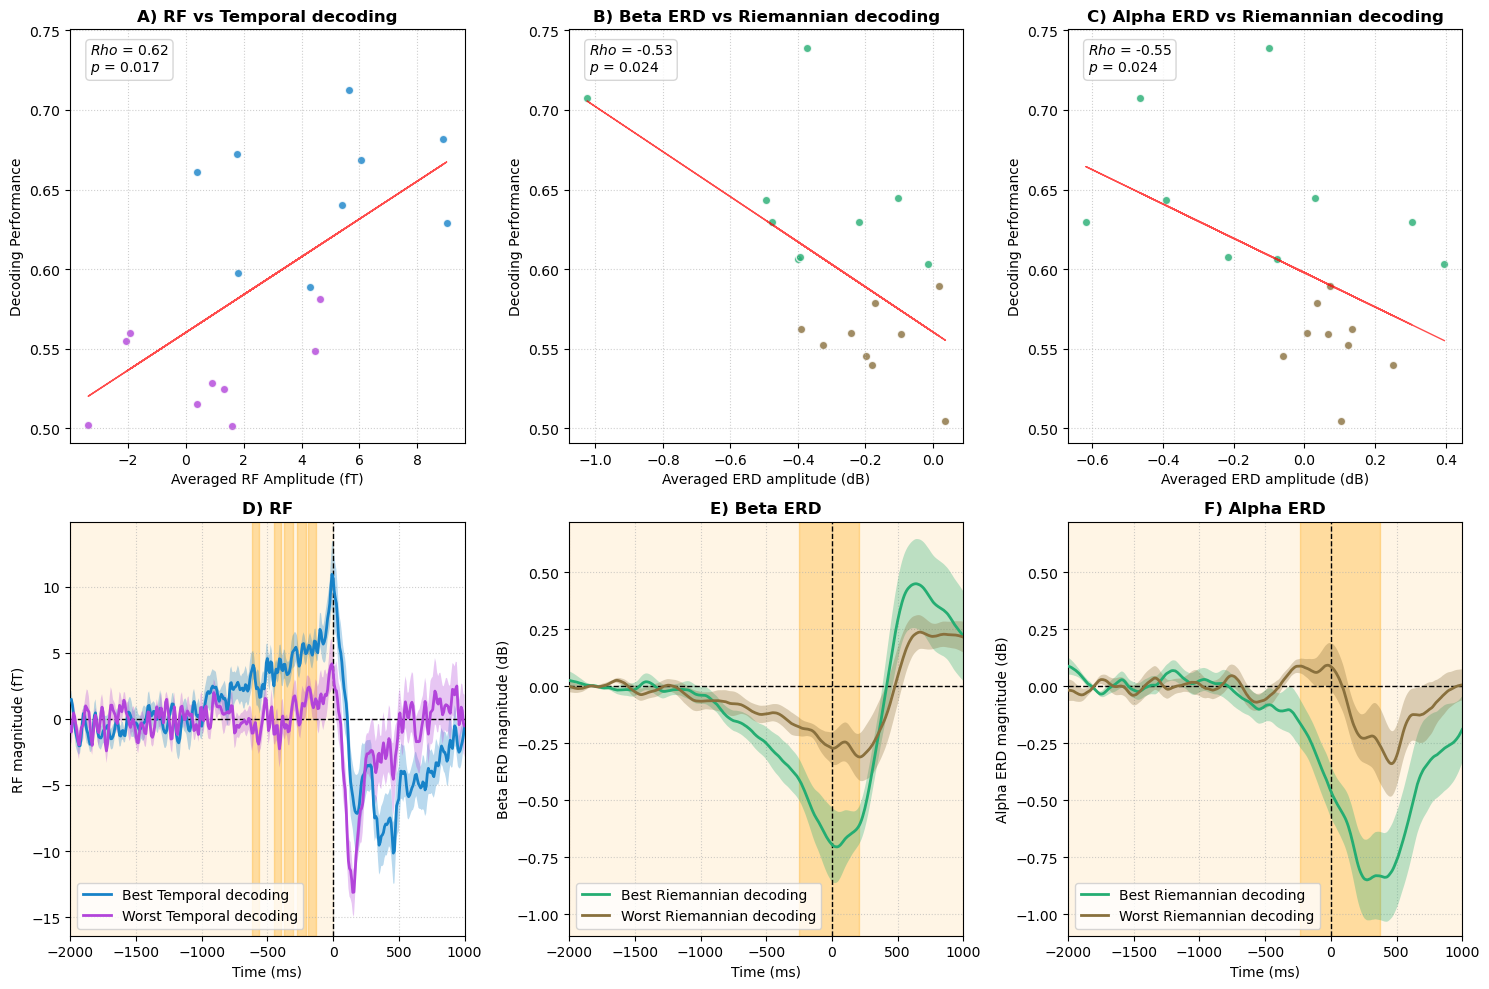

In [ ]:
# Plot the time series of the difference between human and computer for the best and worst decoding performers for RP, beta and alpha markers and highlight the significant clusters on the figure
# Time series grand average for best and worst decoding performers for RP, beta and alpha markers
evoked_plot= [evokeds_diff_RP, evokeds_beta, evokeds_alpha]
clusters_plot = [clusters_diff_RP, clusters_beta, clusters_alpha]
cluster_p_val_plot = [cluster_p_values_diff_RP, cluster_p_values_beta, cluster_p_values_alpha]

# correlation between mean RP/ERD amplitude and temporal/Spectrale decoding performance
mean_MPM_amplitudes = [list_mean_RP_amplitudes, list_mean_beta_amplitudes, list_mean_alpha_amplitudes]
decoding_performances = [list_roc_temporal, list_roc_riemann, list_roc_riemann]
stats_combinaison = [corr_RP, corr_beta_ERD, corr_alpha_ERD]
p_combinaison = [pvals_corr[2], pvals_corr[0], pvals_corr[1]]
# Create boolean masks for significant clusters to use in the plots
sig_masks = [sig_mask_diff_RP, sig_mask_beta, sig_mask_alpha]

# --- Setup Figure ---
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))

# --- Row 1: Correlation Plots ---
titles_corr = ["RF vs Temporal decoding", "Beta ERD vs Riemannian decoding", "Alpha ERD vs Riemannian decoding"]

for i in range(3):
    ax = axes[0, i]
    x, y = mean_MPM_amplitudes[i], decoding_performances[i]
    if i == 0:  # RP
        indices_best = indices_best_temporal 
        indices_worst = indices_worst_temporal 
    else:  # Beta and Alpha
        indices_best = indices_best_spectral 
        indices_worst = indices_worst_spectral
    x1 = [x[i] for i in indices_best]
    y1 = [y[i] for i in indices_best]
    x2 = [x[i] for i in indices_worst]
    y2 = [y[i] for i in indices_worst]

    if i == 0:
        ax.scatter(x1, y1, color= "#1782c8", alpha=0.8, edgecolors='w')
        ax.scatter(x2, y2, color= "#b244da", alpha=0.8, edgecolors='w')
    else:
        ax.scatter(x1, y1, color= "#24ad72", alpha=0.8, edgecolors='w')
        ax.scatter(x2, y2, color= "#89703d", alpha=0.8, edgecolors='w')        
        
    r_val = stats_combinaison[i]
    p_val = p_combinaison[i]

    if p_val < 0.05:  # RP Trendline
        m, b = np.polyfit(x, y, 1)
        ax.plot(x, m*np.array(x) + b, color='red', linestyle='-', linewidth=1, alpha=0.7)

    stats_text = (f"$Rho$ = {r_val:.2f}\n$p$ = {p_val:.2e}" 
                if p_val < 0.001 
                else f"$Rho$ = {r_val:.2f}\n$p$ = {p_val:.3f}")

    ax.text(0.05, 0.97, stats_text, transform=ax.transAxes, 
            verticalalignment='top', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='0.8'))
    

    
    ax.set_title(f"{chr(65+i)}) {titles_corr[i]}", fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_xlabel('Averaged RF Amplitude (fT)' if i == 0 else 'Averaged ERD amplitude (dB)')
    ax.set_ylabel('Decoding Performance')

# --- Row 2: Time Series with SEM and Significance ---
titles_plot = ["RF", "Beta ERD", "Alpha ERD"]
line_styles = ['-', '-']
labels_evoked = ['Best Decoding', 'Worst Decoding']

for i in range(3):
    ax = axes[1, i]
    
    # Data assignment logic
    if i == 0: # RP
        labels = ['Best Temporal decoding', 'Worst Temporal decoding']
        colors = ["#1782c8", "#b244da"]
        data_groups = {'Best Temporal decoding': np.array(list_array_RP_diff_best),
                       'Worst Temporal decoding': np.array(list_array_RP_diff_worst)}
        scale, ylabel = 1e15, 'RF magnitude (fT)'
    elif i == 1: # Beta
        labels = ['Best Riemannian decoding', 'Worst Riemannian decoding']
        colors = ["#24ad72", "#89703d"] 
        data_groups = {'Best Riemannian decoding': np.array(list_array_beta_best),
                       'Worst Riemannian decoding': np.array(list_array_beta_worst)}
        scale, ylabel = 1, 'Beta ERD magnitude (dB)'
    else: # Alpha
        labels = ['Best Riemannian decoding', 'Worst Riemannian decoding']
        colors = ["#24ad72", "#89703d"]
        data_groups = {'Best Riemannian decoding': np.array(list_array_alpha_best),
                       'Worst Riemannian decoding': np.array(list_array_alpha_worst)}
        scale, ylabel = 1, 'Alpha ERD magnitude (dB)'

    # Plot Time Series and SEM
    for label, label_evoked, color, style in zip(labels, labels_evoked, colors, line_styles):
        raw_data = data_groups[label] * scale
        times = evoked_plot[i][label_evoked].times * 1000 
        
        mean_data = np.mean(raw_data, axis=0)
        sem_data = np.std(raw_data, axis=0) / np.sqrt(raw_data.shape[0])
        
        ax.plot(times, mean_data, label=label, color=color, linewidth=2, zorder=3, linestyle=style)
        ax.fill_between(times, mean_data - sem_data, mean_data + sem_data, 
                        color=color, alpha=0.3, edgecolor='none', zorder=2)
        ax.set_xlim(times[0], times[-1])
    # --- Significance Shading ---
    if i == 0:
        test_range = (times >= -2000) & (times <= 0)

        ax.fill_between(times, 0, 1, where=test_range, color='orange', alpha=0.1, 
                            transform=ax.get_xaxis_transform(), zorder=1)
    else:
        test_range = (times >= -2000) & (times <= 1000)

        ax.fill_between(times, 0, 1, where=test_range, color='orange', alpha=0.1, 
                            transform=ax.get_xaxis_transform(), zorder=1)

    current_mask = sig_masks[i] 
    if np.any(current_mask):
        ax.fill_between(times, 0, 1, where=current_mask, color='orange', alpha=0.3, 
                        transform=ax.get_xaxis_transform(), zorder=1)

    # Aesthetics
    ax.set_title(f"{chr(68+i)}) {titles_plot[i]}", fontweight='bold')
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel(ylabel)
    ax.axvline(0, color='black', linestyle='--', linewidth=1) 
    ax.axhline(0, color='black', linestyle='--', linewidth=1) 
    ax.legend( loc='lower left')
    ax.grid(True, linestyle=':', alpha=0.6)

# --- Synchronize Y-limits for Beta (axes[1,1]) and Alpha (axes[1,2]) ---
ylim_beta = axes[1, 1].get_ylim()
ylim_alpha = axes[1, 2].get_ylim()

common_min = min(ylim_beta[0], ylim_alpha[0])
common_max = max(ylim_beta[1], ylim_alpha[1])

axes[1, 1].set_ylim(common_min, common_max)
axes[1, 2].set_ylim(common_min, common_max)

# --- Synchronize Y-limits for Row 1 (Correlation plots) ---
ylim_row1 = [axes[0, i].get_ylim() for i in range(3)]

common_min_row1 = min(lim[0] for lim in ylim_row1)
common_max_row1 = max(lim[1] for lim in ylim_row1)

for i in range(3):
    axes[0, i].set_ylim(common_min_row1, common_max_row1)

plt.tight_layout()
plt.show()